# Ceteris Paribus on Aurora Small with ERA5

This notebook loads the public **Aurora 0.25° Small** checkpoint, builds a batch from one day of
ERA5 the way Aurora's own documentation does, and sends a Ceteris Paribus probe through it with
xsonde: specific humidity is shifted by whole standard deviations and the response of the
2 m temperature and mean sea-level pressure forecasts is read back.

Requirements:

```bash
pip install "xsonde[aurora]" cdsapi matplotlib
```

ERA5 comes from the Copernicus Climate Data Store, which needs an account and a `~/.cdsapirc`
file with your key. The first run downloads about 1.2 GB into `examples/data/`; the requests
wait in the CDS queue, so allow anything from ten minutes to an hour.

Aurora runs at any resolution, so `RES` below picks the grid. At the native 0.25° a forward
pass needs a GPU with 8 GB or more, or a CPU with 16 GB of RAM and a few minutes per pass.
At 1° (the ERA5 fields averaged over 4×4 blocks) it fits in about 1 GB and takes seconds,
which is the setting for a laptop.

In [1]:
import os
import sys
from datetime import datetime
from functools import partial

import numpy as np
import torch
import matplotlib.pyplot as plt

sys.path.insert(0, ".")
from era5_loader import box, download, load_batch
from xsonde import METHODS, results
from xsonde.adapters import AuroraAdapter

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_num_threads(os.cpu_count())
START = datetime(2023, 1, 1, 0)
RES = 1.0
device

/Users/dimitriosdekas/miniconda3/envs/xsonde/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


'cpu'

## Data

`download` fetches the static fields (geopotential, land-sea mask, soil type), the four surface
variables and the five atmospheric variables on Aurora's 13 pressure levels for one day, at
00, 06, 12 and 18 UTC. Files that already exist are skipped.

In [2]:
paths = download(START)
paths

2026-11-03 12:55:29,290 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.


{'static': '/Users/dimitriosdekas/Desktop/xsonde/examples/data/static.nc',
 'surface': '/Users/dimitriosdekas/Desktop/xsonde/examples/data/2023-01-01-surface-level.nc',
 'atmos': '/Users/dimitriosdekas/Desktop/xsonde/examples/data/2023-01-01-atmospheric.nc'}

## Model and adapter

The adapter is the only thing xsonde needs to know about Aurora. `load_batch` is the loader from
`era5_loader.py`: it returns an Aurora `Batch` whose two input steps are `START` and six hours
later, so the forecast is valid twelve hours after `START`. The `resolution` argument coarsens
the ERA5 fields to `RES` before the batch is built.

In [3]:
try:
    from aurora import AuroraSmallPretrained as AuroraSmall
except ImportError:
    from aurora import AuroraSmall

model = AuroraSmall()
model.load_checkpoint("microsoft/aurora", "aurora-0.25-small-pretrained.ckpt")
model = model.to(device).eval()

adapter = AuroraAdapter(model=model, loader=partial(load_batch, resolution=RES), device=device)
batch = adapter.load_batch(START)
{k: tuple(v.shape) for k, v in batch.surf_vars.items()}

{'2t': (1, 2, 180, 360),
 '10u': (1, 2, 180, 360),
 '10v': (1, 2, 180, 360),
 'msl': (1, 2, 180, 360)}

## Unperturbed forecast

A sanity check before probing: the adapter's `predict` returns a dict of physical fields.

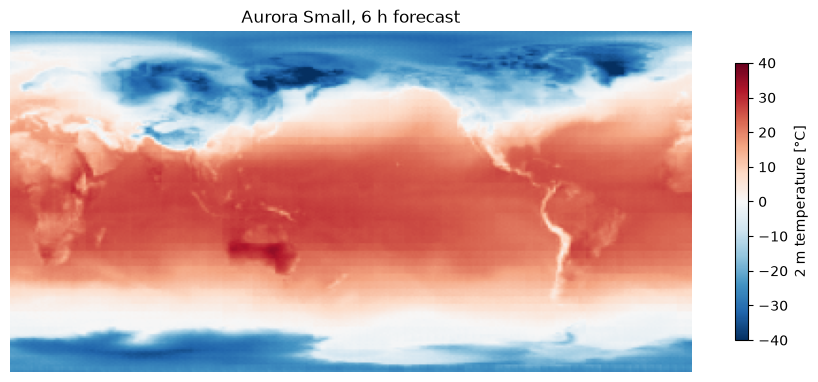

In [4]:
with torch.inference_mode():
    pred = adapter.predict(batch)

t2 = pred["2t"][0, 0].cpu().numpy() - 273.15
plt.figure(figsize=(11, 4.5))
plt.imshow(t2, cmap="RdBu_r", vmin=-40, vmax=40)
plt.colorbar(label="2 m temperature [°C]", shrink=0.8)
plt.title("Aurora Small, 6 h forecast")
plt.axis("off")
plt.show()

## The probe

A probe is a source, a list of targets and a list of reductions. Here the source is specific
humidity at every level, shifted by −3σ to +3σ in the model's normalised space (`mode: dist`),
and each target field is reduced to a global mean, a mean over Europe, the RMS change against
the unperturbed forecast, and its spatial spread. `box` turns a latitude-longitude box into
grid indices at the chosen resolution.

In [5]:
EUROPE = box(60, 40, 0, 30, RES)

probe = METHODS["ceteris_paribus"]({
    "source": "q",
    "targets": ["2t", "msl"],
    "mode": "dist",
    "perturbations": [-3, -2, -1, 0, 1, 2, 3],
    "reductions": [
        {"name": "global_mean", "label": "globalMean"},
        {"name": "regional_mean", "label": "europe", **EUROPE},
        {"name": "rmse_response", "label": "rmseResp"},
        {"name": "spatial_std", "label": "spatialStd"},
    ],
})
result = probe.run(adapter, batch)
result.results["2t"]["rmseResp"]

[3.9658529070198014,
 3.1590320139874675,
 1.7027644123019752,
 0.0,
 0.5708253417031143,
 0.9450325852586184,
 1.198864102775871]

## Response curves

The thesis convention: the RMS response of each target, divided by the spatial spread of the
unperturbed forecast, so the two targets are comparable.

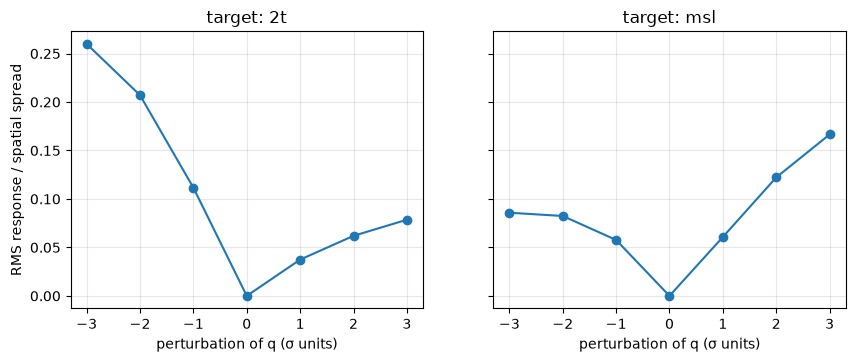

In [6]:
deltas = result.meta["perturbations"]
base = deltas.index(0)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, target in zip(axes, probe.cfg.targets):
    r = result.results[target]
    ax.plot(deltas, np.array(r["rmseResp"]) / r["spatialStd"][base], marker="o")
    ax.set_title(f"target: {target}")
    ax.set_xlabel("perturbation of q (σ units)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("RMS response / spatial spread")
plt.show()

## Response map

`result.fields` holds the full forecast field for every perturbation, so the difference between
the +1σ and the unperturbed forecast shows where the model moves.

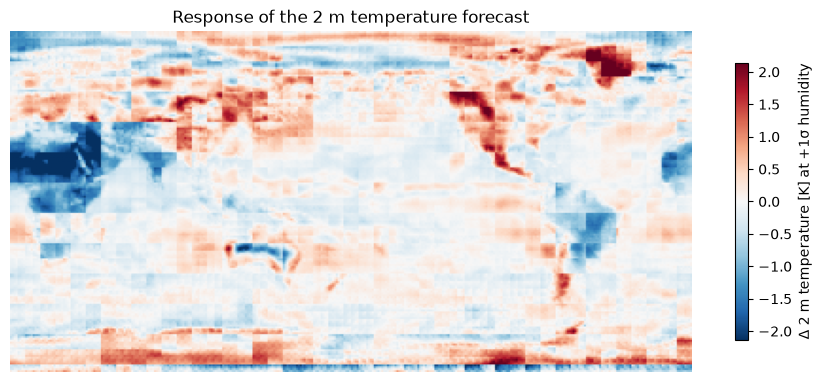

In [7]:
diff = result.fields["2t"][deltas.index(1)] - result.fields["2t"][base]
lim = np.percentile(np.abs(diff), 99)

plt.figure(figsize=(11, 4.5))
plt.imshow(diff, cmap="RdBu_r", vmin=-lim, vmax=lim)
plt.colorbar(label="Δ 2 m temperature [K] at +1σ humidity", shrink=0.8)
plt.title("Response of the 2 m temperature forecast")
plt.axis("off")
plt.show()

## Saving

Results are written as netCDF plus JSON and come back as the same `Result` object, or as xarray
datasets for your own analysis.

In [8]:
out = "runs/cp_q_2t_msl"
results.save(result, out)
loaded = results.load(out)
loaded.to_datasets()["2t"]

<xarray.Dataset> Size: 2MB
Dimensions:  (sample: 7, lat: 180, lon: 360)
Coordinates:
  * sample   (sample) int64 56B 0 1 2 3 4 5 6
  * lat      (lat) float64 1kB 89.62 88.62 87.62 86.62 ... -87.38 -88.38 -89.38
  * lon      (lon) float64 3kB 0.375 1.375 2.375 3.375 ... 357.4 358.4 359.4
Data variables:
    fields   (sample, lat, lon) float32 2MB 250.1 250.5 250.0 ... 248.1 248.7

## From a notebook to a sweep

The same probe as a yaml file is in `sweeps/aurora_small_era5.yaml`. It declares the adapter,
the date and the method once, and a `sweep` block expands it over sources and dates:

```bash
PYTHONPATH=. xsonde run sweeps/aurora_small_era5.yaml
```

Inside a SLURM job with several tasks the runs are sharded across tasks automatically, and runs
that already carry a `done` marker are skipped on resubmission.